# Main idea:
I have here 3 main questions to check:
1. When split the path with a conflict, does the model look ahead for a final answer? e.g. 1 path has an answer and the other doesn't. maybe the one with no answer can be memory and see if the memory is stronger than an actual answer.
2. When split the path with a conflict, will the model take a shorter path? e.g. both have answer with different number of hops.
3. Does these phenomenas will change if a multi hop process has already started? e.g the split is in a later stage of the reasoning chain.

In [8]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import random
import numpy as np
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

def save_json(file_name, file):
    with open(os.path.join(REPO_PATH, "data_files", f"{file_name}.json"), "w", encoding="utf-8") as out_file:
        json.dump(file, out_file, indent=4)


def load_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f]

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [25]:
import re

def classify_decomposition(decomposition: str) -> str:
    """
    Classify a decomposition as 'chain', 'compositional', or 'single-hop'.
    Input is a multiline string with steps (your format).
    """
    steps = [s.strip() for s in decomposition.split("\n") if s.strip()]
    if len(steps) == 1:
        return "single-hop"
    
    # Extract references (#1, #2, …) from each step
    references = [re.findall(r"#\d+", step) for step in steps]
    
    # Check if it's a linear chain
    is_chain = True
    for i in range(1, len(steps)):
        expected = f"#{i}"
        if expected not in steps[i]:
            is_chain = False
            break
    
    # Detect compositional signals
    has_multi_refs = any(len(refs) > 1 for refs in references)
    has_skips = any(
        f"#{i}" in step and f"#{i-1}" not in step
        for i, step in enumerate(steps[1:], start=1)
    )
    
    if is_chain and not has_multi_refs and not has_skips:
        return "chain"
    elif has_multi_refs or has_skips:
        return "compositional"
    else:
        return "chain"  # fallback: shallow chain

In [10]:
musique_dev = load_jsonl("C:/Users/Daniel/Desktop\musique_data_v1.0\data\musique_ans_v1.0_dev.jsonl")

In [19]:
random.sample([sample['question_decomposition'] for sample in musique_dev], 20)

[[{'id': 804367,
   'question': 'Kot Haibat >> country',
   'answer': 'Pakistan',
   'paragraph_support_idx': 7},
  {'id': 160713,
   'question': 'What was the majority religion in the area of British India that become India when #1 was created?',
   'answer': 'Hindu',
   'paragraph_support_idx': 14},
  {'id': 77246,
   'question': 'what is the meaning of #2 in arabic dictionary',
   'answer': 'the country of India',
   'paragraph_support_idx': 10}],
 [{'id': 28841,
   'question': 'Who composed the Concerto in C Major Op 3 6?',
   'answer': 'Antonio Vivaldi',
   'paragraph_support_idx': 1},
  {'id': 547811,
   'question': '#1 >> place of birth',
   'answer': 'Venice',
   'paragraph_support_idx': 11},
  {'id': 41132,
   'question': 'How many times did plague occur in #2 ?',
   'answer': '22',
   'paragraph_support_idx': 15}],
 [{'id': 108336,
   'question': "Which was the creator of Allegory of Isabella d'Este's Coronation?",
   'answer': 'Lorenzo Costa',
   'paragraph_support_idx': 0},

In [42]:
processed_data = []
question_subset = musique_dev #random.sample(musique_dev, 100)
ids = [sample['id'] for sample in question_subset]
questions = [sample['question'] for sample in question_subset]
meta = [sample['question_decomposition'] for sample in question_subset]
summary = []
for ques, deco, idx in zip(questions, meta, ids):
    num_hops = int(idx[0])
    # print(idx[0])
    all_text = ""
    all_text += f"Question: {ques}\n"
    all_text += "Decomposition:\n"
    for step in deco:
        all_text += f"{step['question']} --> {step['answer']}\n"
    answer_class = classify_decomposition(all_text)
    summary.append((answer_class, num_hops))
    processed_data.append({'text': all_text,
                           'type': (answer_class, num_hops)})
    # print(all_text)
    # print(classify_decomposition(all_text))
    # print('-'*100)

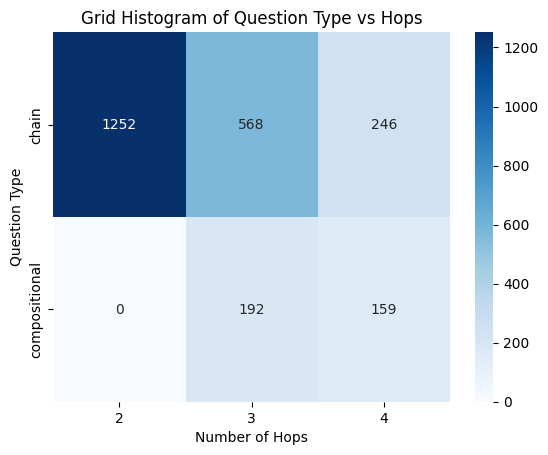

In [39]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Convert to DataFrame
df = pd.DataFrame(summary, columns=['type', 'hops'])

# Create pivot table for grid
grid = df.pivot_table(index='type', columns='hops', aggfunc='size', fill_value=0)

# Plot heatmap
sns.heatmap(grid, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Number of Hops')
plt.ylabel('Question Type')
plt.title('Grid Histogram of Question Type vs Hops')
plt.show()

In [48]:
conditioned_data = [item['text'] for item in processed_data if item['type'][0] == 'chain' and item['type'][1] == 4]

In [51]:
sample_dataset = random.sample(conditioned_data, 10)

In [52]:
for i in sample_dataset:
    print(i)

Question: Where is the district that the person who wanted to reform and address Medardo Joseph Mazombwe's religion preached a sermon on Marian devotion before his death located?
Decomposition:
Medardo Joseph Mazombwe >> religion --> Catholic Church
who wanted #1 to reform and address --> Martin Luther
Where did #2 preach a sermon on Marian devotion a month before his death? --> Wittenberg
#3 >> located in the administrative territorial entity --> Saxony-Anhalt

Question: When was the all-star game played for the league that includes the team with the most titles won just before the mlb mvp is awarded?
Decomposition:
when do they give out the mlb mvp award --> after the World Series
what team has the most #1 titles --> the New York Yankees
Which is the league of #2 ? --> Major League Baseball
when is the #3 all-star game being played --> July 11, 2017

Question: Who is the son of the Italian navigator who explored the eastern coast of the continent Ulises Solís' birthplace is located i

In [63]:
from knowledge_maze.tools.api_tools import *

# Initialize LLM prompts:
COUNTERFACTUAL_DECOMP_PROMPT = """
You are given a question with its decomposition steps. Each step has a question and its answer.
Your task is to generate TWO different counterfactual alternative decomposition paths.

Rules:
1. Replace the first answer in each path with a plausible but factually incorrect alternative.  
2. Update all subsequent steps consistently so they follow logically from the new first answer.  
3. Keep the answers plausible and coherent with the type of entity expected (e.g., if the original answer is a religion, the counterfactual should also be a religion).  
4. The two decompositions must be contradictory to each other (i.e., not leading to the same final answer).  
5. The final decompositions must both be self-consistent.  
6. Output only a tuple of size 2, where each element is a string of one full counterfactual decomposition.  

Example Input:
Question: Where is the district that the person who wanted to reform and address Medardo Joseph Mazombwe's religion preached a sermon on Marian devotion before his death located?
Decomposition:
Medardo Joseph Mazombwe >> religion --> Catholic Church
who wanted #1 to reform and address --> Martin Luther
Where did #2 preach a sermon on Marian devotion a month before his death? --> Wittenberg
#3 >> located in the administrative territorial entity --> Saxony-Anhalt

Example Output:
(
"Counterfactual Decomposition:\nMedardo Joseph Mazombwe >> religion --> Anglicanism\nwho wanted #1 to reform and address --> John Wesley\nWhere did #2 preach a sermon on Marian devotion a month before his death? --> London\n#3 >> located in the administrative territorial entity --> Greater London",
"Counterfactual Decomposition:\nMedardo Joseph Mazombwe >> religion --> Eastern Orthodoxy\nwho wanted #1 to reform and address --> Patriarch Nikon\nWhere did #2 preach a sermon on Marian devotion a month before his death? --> Moscow\n#3 >> located in the administrative territorial entity --> Russia"
)

Now use the same method on the following input:

Question: {original_question}
Decomposition:
{step_1_question} --> {step_1_answer}
{step_2_question} --> {step_2_answer}
...
"""

# Create LLM API call object:
counterfactual_model = gptAPI(
    COUNTERFACTUAL_DECOMP_PROMPT,
    output_format='list',
    temperature=0.8,
    max_concurrent_requests=100,
    max_rpm=4900
)

In [64]:
results = await counterfactual_model.async_run(sample_dataset)

for inp, res in zip(sample_dataset, results):
    alt1, alt2 = res
    print("Original:\n", inp)
    print("\nAlternative 1:\n", alt1)
    print("\nAlternative 2:\n", alt2)

Usage cost: 0.0017$ (Estimated: 0.00$): 100%|██████████████████████████████████████████| 10/10 [00:04<00:00,  2.43it/s]

Original:
 Question: Where is the district that the person who wanted to reform and address Medardo Joseph Mazombwe's religion preached a sermon on Marian devotion before his death located?
Decomposition:
Medardo Joseph Mazombwe >> religion --> Catholic Church
who wanted #1 to reform and address --> Martin Luther
Where did #2 preach a sermon on Marian devotion a month before his death? --> Wittenberg
#3 >> located in the administrative territorial entity --> Saxony-Anhalt


Alternative 1:
 Counterfactual Decomposition:
Medardo Joseph Mazombwe >> religion --> Lutheranism
who wanted #1 to reform and address --> Huldrych Zwingli
Where did #2 preach a sermon on Marian devotion a month before his death? --> Zurich
#3 >> located in the administrative territorial entity --> Canton of Zurich

Alternative 2:
 Counterfactual Decomposition:
Medardo Joseph Mazombwe >> religion --> Methodism
who wanted #1 to reform and address --> John Wesley
Where did #2 preach a sermon on Marian devotion a month 

In [65]:
from knowledge_maze.tools.api_tools import *

# Prompt template for paragraph generation
ANSWER_PARAGRAPH_PROMPT = """
You are given a question decomposition, where each step has an answer entity.
Your task is to generate a short factual-style paragraph (2–4 sentences) about each answer.
Write the paragraphs as if they were taken from a reliable encyclopedia or factual article.
Keep them coherent, neutral, and informative, but concise.

Input format:
Question: {original_question}
Decomposition:
{step_1_question} --> {step_1_answer}
{step_2_question} --> {step_2_answer}
...

Output format:
Paragraphs:
{step_1_answer}: {short factual paragraph}
{step_2_answer}: {short factual paragraph}
{step_3_answer}: {short factual paragraph}
...
"""

# Create the model
answer_paragraph_model = gptAPI(
    ANSWER_PARAGRAPH_PROMPT,
    output_format='list',
    temperature=0.7,   # lower temp = more factual/consistent
    max_concurrent_requests=100,
    max_rpm=4900
)

In [66]:
decompositions = []
for sample in results:
    for a in sample:
        decompositions.append(a)

In [71]:
paras = await answer_paragraph_model.async_run(decompositions)

Usage cost: 0.0037$ (Estimated: 0.00$): 100%|██████████████████████████████████████████| 20/20 [00:12<00:00,  1.58it/s]


In [75]:
print(paras[0])

Paragraphs:
Lutheranism: Lutheranism is a major branch of Protestant Christianity that identifies with the theological traditions and teachings of Martin Luther, a 16th-century German monk and reformer. It emphasizes salvation by faith alone, the authority of Scripture, and the priesthood of all believers, rejecting certain practices of the Catholic Church. Lutheranism has spread globally, influencing various cultures and societies.
Huldrych Zwingli: Huldrych Zwingli was a Swiss Protestant reformer and a key figure in the Reformation, best known for his role in the development of Reformed Christianity. He advocated for a return to the Scriptures and sought to reform the church's practices, particularly in Zurich, where he preached and implemented significant changes in worship and doctrine.
Zurich: Zurich is the largest city in Switzerland and serves as the capital of the Canton of Zurich. It is known for its rich history, economic significance, and cultural institutions. The city play

In [93]:
test_context = [p.split(":", 1)[1].strip().split("\n") for p in paras]
test_context = [item for sublist in test_context for item in sublist]

In [96]:
def extract_final_answer(decomposition: str) -> str:
    """Extract the final answer (after the last -->) from a decomposition string."""
    return decomposition.strip().split("-->")[-1].strip()


meta_data_test = []

for inp, res in zip(sample_dataset, results):
    alt1, alt2 = res

    entry = {
        "question": inp.split("\n")[0].replace("Question: ", "").strip(),
        "answers": {
            "memory_answer": extract_final_answer(inp),
            "alt1": extract_final_answer(alt1),
            "alt2": extract_final_answer(alt2),
        }
    }

    meta_data_test.append(entry)

In [116]:
from knowledge_maze.tools.api_tools import *

# Prompt for answering from a provided context
ASK_FROM_CONTEXT_PROMPT = f"""
You are a knowledgeable AI assistant. 
You will be given a question. 
Answer the question strictly based on the provided context. 

Rules:
- Do not use outside knowledge.
- Keep the answer concise and factual.
- try to find the most suitable answer in the context.

This is the provided context:
{random.shuffle(test_context)}
"""

# Create LLM API call object
qa_context_model = gptAPI(
    ASK_FROM_CONTEXT_PROMPT,
    output_format='list',
    temperature=1.0,
    max_concurrent_requests=100,
    max_rpm=4900
)

In [117]:
questions = [sample['question'] for sample in meta_data_test]

In [118]:
answers = await qa_context_model.async_run(questions)

Usage cost: 0.0003$ (Estimated: 0.00$): 100%|██████████████████████████████████████████| 10/10 [00:01<00:00,  6.84it/s]


In [120]:
answers

[['The context does not provide information about the location of the district related to Medardo Joseph Mazombwe.'],
 ['There is no provided context regarding the specific league or team with the most titles, nor any information about an all-star game or MVP award.'],
 ["The context does not provide information about any Italian navigator or Ulises Solís' birthplace."],
 ['1992'],
 ["The context does not provide information about the direction of flow of the body of water or the city sharing a border with Elizabeth Berg's birthplace."],
 ['The provided context does not contain information about the creation date of the region that lies to the north of Aluf and the Persian Gulf.'],
 ['The context does not specify the state where the district is located.'],
 ['Phoenix, Arizona', 'Los Angeles, California'],
 ['Harvard Medical School', 'Austria'],
 ['Williamson County, Tennessee']]

In [115]:
meta_data_test

[{'question': "Where is the district that the person who wanted to reform and address Medardo Joseph Mazombwe's religion preached a sermon on Marian devotion before his death located?",
  'answers': {'memory_answer': 'Saxony-Anhalt',
   'alt1': 'Canton of Zurich',
   'alt2': 'England'}},
 {'question': 'When was the all-star game played for the league that includes the team with the most titles won just before the mlb mvp is awarded?',
  'answers': {'memory_answer': 'July 11, 2017',
   'alt1': 'February 19, 2017',
   'alt2': 'January 31, 2017'}},
 {'question': "Who is the son of the Italian navigator who explored the eastern coast of the continent Ulises Solís' birthplace is located in for England?",
  'answers': {'memory_answer': 'Sebastian Cabot',
   'alt1': 'Francesco Vespucci',
   'alt2': 'Piero da Verrazzano'}},
 {'question': 'When did the country whose co-official language was used in the show named for the place Slavko Surdonja died first attend the Olympics games as an independe